# Giornata 1 — Simulazione Monte Carlo
## Fase preliminare
Studiamo un modello di frange di intensità luminosa prodotte da interferenza e diffrazione. In questa fase definiamo i parametri del modello, le posizioni di misura e le funzioni che costruiscono il modello.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# stile comune del corso
# colori: AZZURRO dati e simulazioni, ROSSO modello e fit, GRIGIO riferimenti, ARANCIONE confronti, ORO mediana
ROSSO = "#C92512"
GRIGIO = "#5A5A5A"
AZZURRO = "#2E6F9E"
ORO = "#D79B00"
ARANCIONE = "#FFA500"
plt.rcParams.update(
    {
        "figure.figsize": (8.2, 4.6),
        "figure.dpi": 120,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "font.size": 11,
        "legend.frameon": False,
    }
)

# parametri del modello
B = 20  # fondo uniforme (conteggi per bin)
I0 = 400  # scala del segnale (conteggi per bin)
alpha = 0.90  # larghezza dell'inviluppo (mm^-1)
delta = 5.20  # frequenza spaziale delle frange (mm^-1)

x = np.linspace(-5.0, 5.0, 161)  # 161 punti equidistanti (mm)
centro = np.abs(x) < 1.2  # regione centrale

rng = np.random.default_rng(120)  # generatore locale, inizializzato una sola volta


def E(x, alpha):
    return np.sinc(alpha * x / np.pi) ** 2


def C(x, delta):
    return np.cos(delta * x) ** 2


def mu(x, B, I0, alpha, delta):
    return B + I0 * E(x, alpha) * C(x, delta)

## Attività 1
Costruiamo il modello fisico e lo rappresentiamo insieme al fondo e all'inviluppo superiore. Il numero medio atteso di conteggi nel punto $x$ è
$$ \mu(x) = B + I_0 \, E(x) \, C(x), \qquad E(x) = \left[\frac{\sin(\alpha x)}{\alpha x}\right]^2, \qquad C(x) = \cos^2(\delta x) $$
Verifichiamo che $\mu$ sia finita, non negativa, simmetrica e compatibile con $\mu(0) = B + I_0$.

mu finita: True
mu non negativa: True
mu simmetrica: True
mu(0) = B + I0: True


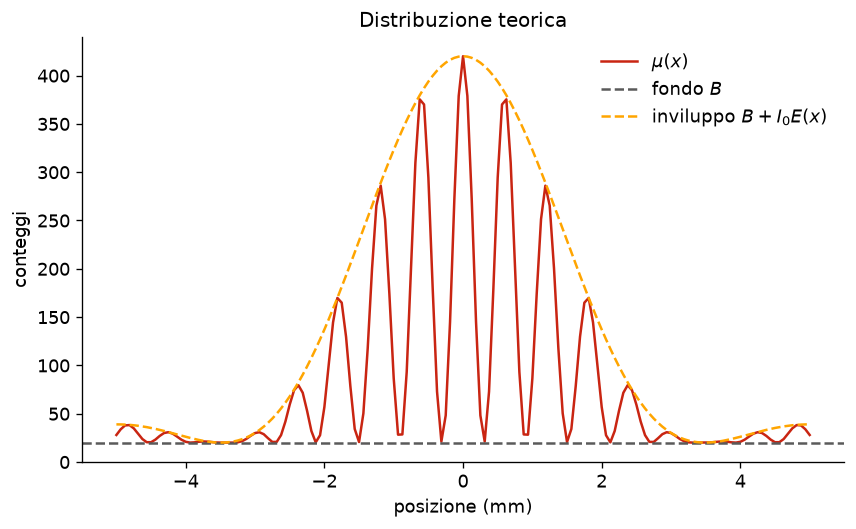

In [2]:
mu_x = mu(x, B, I0, alpha, delta)

print(f"mu finita: {np.all(np.isfinite(mu_x))}")
print(f"mu non negativa: {np.all(mu_x >= 0)}")
print(f"mu simmetrica: {np.allclose(mu_x, mu_x[::-1])}")
print(f"mu(0) = B + I0: {np.isclose(mu(0.0, B, I0, alpha, delta), B + I0)}")

fig, ax = plt.subplots()
ax.plot(x, mu_x, color=ROSSO, label=r"$\mu(x)$")
ax.axhline(B, color=GRIGIO, ls="--", label=r"fondo $B$")
ax.plot(x, B + I0 * E(x, alpha), color=ARANCIONE, ls="--", label=r"inviluppo $B + I_0 E(x)$")
ax.set(xlabel="posizione (mm)", ylabel="conteggi", title="Distribuzione teorica")
ax.legend()
plt.show()

$\alpha$ controlla la larghezza del massimo centrale (primo minimo dell'inviluppo in $x = \pi/\alpha$), $\delta$ la distanza tra le frange ($\pi/\delta$).

La funzione non ha singolarità in $x = 0$ perché `np.sinc` calcola il limite notevole
$$ \lim_{z \to 0} \frac{\sin z}{z} = 1 $$

## Attività 2
Simuliamo una singola acquisizione: in ogni posizione il conteggio è una variabile di Poisson indipendente
$$ n_i \sim \mathrm{Poisson}(\mu(x_i)) $$
con errore $\sqrt{n_i}$ (nei bin vuoti si usa 1, lo stesso errore verrà usato come $\sigma_y$ nel file dati).

Confrontiamo poi i conteggi nella regione centrale con il valore atteso
$$ N_c = \sum_{|x_i| < 1.2\,\mathrm{mm}} n_i \qquad \mu_c = \sum_{|x_i| < 1.2\,\mathrm{mm}} \mu_i $$

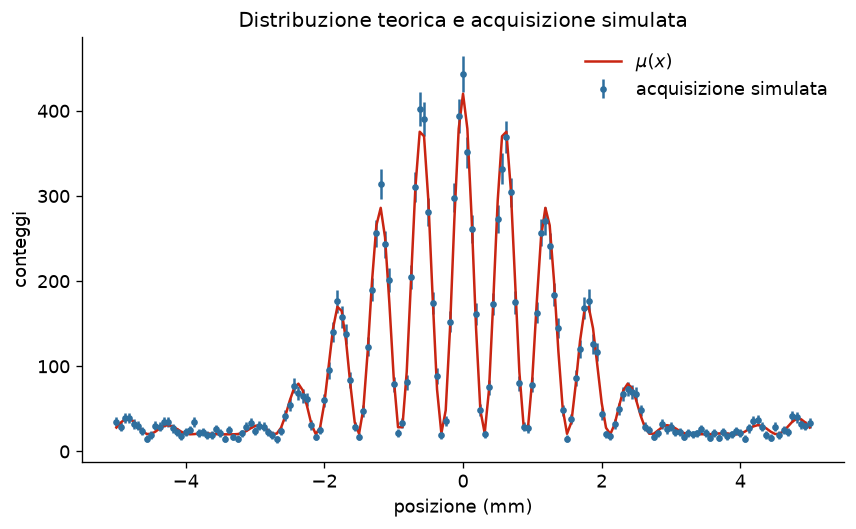

N_c = 7613
mu_c = 7649.4
N_c - mu_c = -36.4
sqrt(mu_c) = 87.5


In [3]:
n = rng.poisson(mu_x)
err_n = np.where(n == 0, 1, np.sqrt(n))

fig, ax = plt.subplots()
ax.errorbar(x, n, err_n, fmt=".", color=AZZURRO, label="acquisizione simulata")
ax.plot(x, mu_x, color=ROSSO, label=r"$\mu(x)$")
ax.set(xlabel="posizione (mm)", ylabel="conteggi", title="Distribuzione teorica e acquisizione simulata")
ax.legend()
plt.show()

N_c = np.sum(n[centro])
mu_c = np.sum(mu_x[centro])
print(f"N_c = {N_c}")
print(f"mu_c = {mu_c:.1f}")
print(f"N_c - mu_c = {N_c - mu_c:.1f}")
print(f"sqrt(mu_c) = {np.sqrt(mu_c):.1f}")

## Attività 3
Ripetiamo l'acquisizione $M = 2000$ volte. Ogni riga della matrice simulata è un esperimento completo
$$ \begin{bmatrix} n^{(1)}_1 & \dots & n^{(1)}_{161} \\ \vdots & & \vdots \\ n^{(2000)}_1 & \dots & n^{(2000)}_{161} \end{bmatrix} $$
e per ognuno calcoliamo
$$ N_c^{(j)} = \sum_{|x_i| < 1.2\,\mathrm{mm}} n_i^{(j)} $$
Confrontiamo media e deviazione standard di $N_c$ con $\mu_c$ e $\sqrt{\mu_c}$.

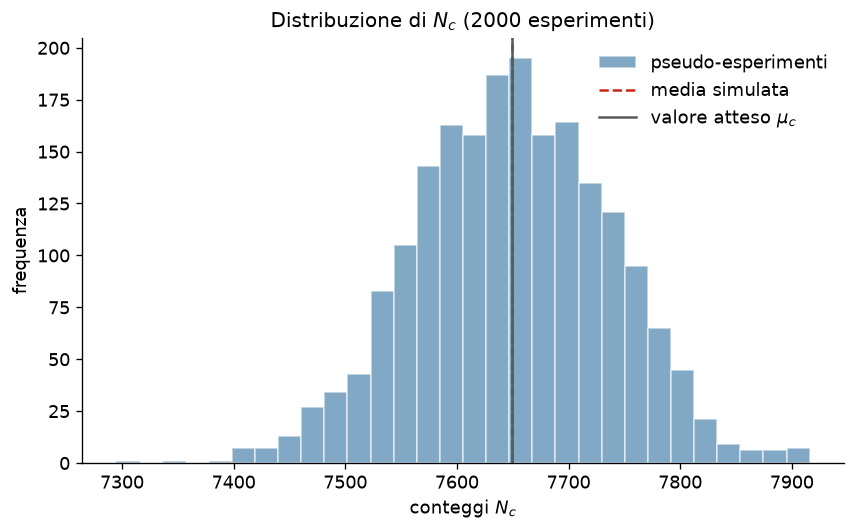

media di N_c = 7649.8
deviazione standard (ddof=1) = 86.9
errore sulla media = 1.9
scarto relativo (media - mu_c) / mu_c = 4.6e-05
sqrt(mu_c) atteso = 87.5


In [4]:
M = 2000
n_mc = rng.poisson(mu_x, size=(M, x.size))
N_c_mc = np.sum(n_mc[:, centro], axis=1)

fig, ax = plt.subplots()
ax.hist(N_c_mc, bins=30, color=AZZURRO, alpha=0.6, edgecolor="white", label="pseudo-esperimenti")
ax.axvline(N_c_mc.mean(), color=ROSSO, ls="--", label="media simulata")
ax.axvline(mu_c, color=GRIGIO, label=r"valore atteso $\mu_c$")
ax.set(xlabel=r"conteggi $N_c$", ylabel="frequenza", title=f"Distribuzione di $N_c$ ({M} esperimenti)")
ax.legend()
plt.show()

print(f"media di N_c = {N_c_mc.mean():.1f}")
print(f"deviazione standard (ddof=1) = {N_c_mc.std(ddof=1):.1f}")
print(f"errore sulla media = {N_c_mc.std(ddof=1) / np.sqrt(M):.1f}")
print(f"scarto relativo (media - mu_c) / mu_c = {(N_c_mc.mean() - mu_c) / mu_c:.1e}")
print(f"sqrt(mu_c) atteso = {np.sqrt(mu_c):.1f}")

## Dati per la giornata 2
Salviamo la prima acquisizione simulata in `dati.csv`, con $\sigma_y = \sqrt{y}$ (1 nei bin vuoti).

In [5]:
y = n_mc[0]
sigma_y = np.where(y == 0, 1, np.sqrt(y))
pd.DataFrame({"x": x, "y": y, "sigma_y": sigma_y}).to_csv("dati.csv", index=False)